In [44]:
import numpy as np
import matplotlib.pyplot as plt

In [61]:
from types import SimpleNamespace


def get_gt():
    jitter = 250
    noise_params = (jitter, jitter * 10)
    T = 100

    noise = np.array([np.random.randint(*noise_params) for i in range(T)])

    x = np.array([i for i in range(T)])
    y = np.array(x**2 + noise)

    return SimpleNamespace(x=x, y=y)

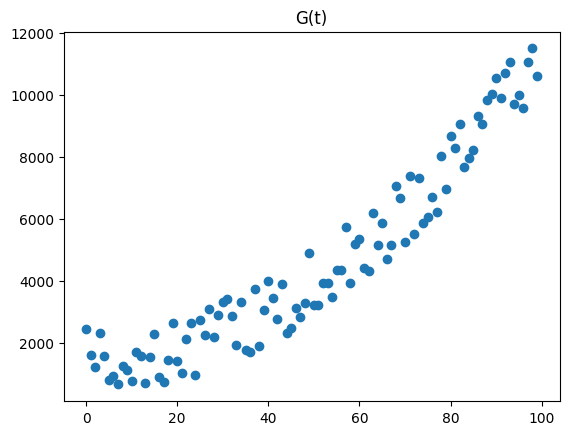

In [62]:
gt = get_gt()

plt.scatter(gt.x, gt.y)
plt.title("G(t)")
plt.show()

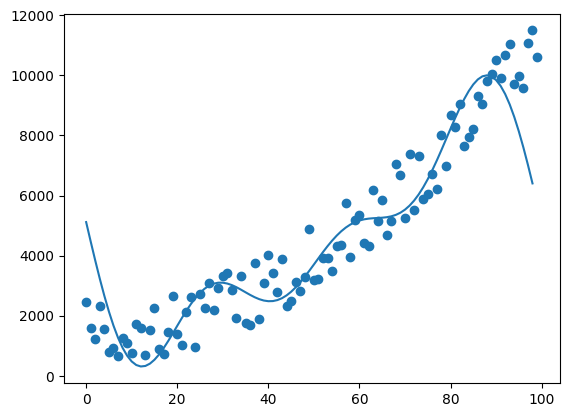

In [ ]:
def xN(
        T, 
        gt_func,
        wave_function = None,
        N = 0,
    ):
    # calculating the integral contents

    conditional = (gt_func.x >= 0) & (gt_func.x <= T)
    relevant_gt_y = gt_func.y[conditional]
    relevant_gt_x = gt_func.x[conditional]
    relevant_gt_x_diffs = np.diff(relevant_gt_x)

    heights = relevant_gt_y[:-1] # we're calculating area of rect
    widths = relevant_gt_x_diffs

    gt_dt = heights * widths

    if N == 0:
        return (2 / T) * np.sum(gt_dt)

    # incorporate wave stuff here
    wave_factor_values = wave_function((2 * np.pi * N * relevant_gt_x[:-1]) / T)
    return (2 / T) * np.sum(gt_dt * wave_factor_values)

def fourier_approximation(t):
    """

    f(t) = (a0/2) + sum(
                (aN x cos((2*pi*n*t) / T)) +
                (bN x sin((2*pi*n*t) / T))
        )

    T is the length of the interval
    N is the number of frequencies
    aN cos-wave weights
    bN sin-wave weights

    a0 = (2/T) x integral (0, T) [ G(t) ] dt
    aN = (2/T) x integral (0, T) [ G(t) cos(2*pi*n*t) ] dt
    bN = (2/T) x integral (0, T) [ G(t) sin(2*pi*n*t) ] dt

    """

    T = 100
    depth = 3

    span = np.arange(1, depth + 1)

    a0 = xN(T=T, gt_func=gt)

    a_elements = np.array([
        xN(T=T, gt_func=gt, wave_function=np.cos, N=n)
        for n in span
    ])
    b_elements = np.array([
        xN(T=T, gt_func=gt, wave_function=np.sin, N=n)
        for n in span
    ])

    a_elements = a_elements * np.cos((2*np.pi*span*t) / T)
    b_elements = b_elements * np.sin((2*np.pi*span*t) / T)


    ft = (a0/2) + np.sum(a_elements + b_elements)

    return ft
    

x = np.arange(0, 99)
predicted_y = []
for i in range(len(x)):
    predicted_y.append(fourier_approximation(i))

plt.scatter(gt.x, gt.y)
plt.plot(x, predicted_y)
plt.show()